In [1]:
# GIS and Geospatial Study
# Task 7: Raster, Vector, CRS and Two-Date Vegetation Comparison

print("GIS and Geospatial Study")
print("Task 7 notebook started successfully!")

GIS and Geospatial Study
Task 7 notebook started successfully!


In [2]:
!pip install -q geopandas rasterio folium matplotlib pandas numpy shapely pyproj

In [3]:
import geopandas as gpd
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium
import shapely
import pyproj

print("GeoPandas:", gpd.__version__)
print("Rasterio:", rasterio.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("All GIS libraries imported successfully!")

GeoPandas: 1.2.0
Rasterio: 1.5.2
NumPy: 2.4.6
Pandas: 2.2.3
All GIS libraries imported successfully!


In [4]:
import geopandas as gpd
from shapely.geometry import Polygon

# Create a fictional wetland study boundary
coordinates = [
    (77.50, 16.50),
    (77.60, 16.50),
    (77.60, 16.60),
    (77.50, 16.60),
    (77.50, 16.50)
]

wetland_polygon = Polygon(coordinates)

# Create GeoDataFrame
gdf = gpd.GeoDataFrame(
    {
        "study_area": ["Wetland Study Area"],
        "location": ["Sample Region"],
        "area_type": ["Wetland"]
    },
    geometry=[wetland_polygon],
    crs="EPSG:4326"
)

# Display vector data
print("Study Area Details:")
print(gdf)

# Save as GeoJSON
gdf.to_file(
    "wetland_boundary.geojson",
    driver="GeoJSON"
)

print("\nGeoJSON file created successfully!")
print("CRS:", gdf.crs)

Study Area Details:
           study_area       location area_type  \
0  Wetland Study Area  Sample Region   Wetland   

                                            geometry  
0  POLYGON ((77.5 16.5, 77.6 16.5, 77.6 16.6, 77....  

GeoJSON file created successfully!
CRS: EPSG:4326


In [5]:
import folium

# Calculate the center of the study area
center_lat = 16.55
center_lon = 77.55

# Create an interactive map
m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=12,
    tiles="OpenStreetMap"
)

# Add GeoJSON boundary to the map
folium.GeoJson(
    gdf,
    name="Wetland Boundary",
    style_function=lambda feature: {
        "fillColor": "green",
        "color": "darkgreen",
        "weight": 3,
        "fillOpacity": 0.4
    },
    tooltip="Wetland Study Area"
).add_to(m)

folium.LayerControl().add_to(m)

# Display map
m

In [6]:
import folium

# Center of the study area
center_lat = 16.55
center_lon = 77.55

# Create map without external map tiles
m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=12,
    tiles=None
)

# Add the wetland boundary
folium.GeoJson(
    gdf,
    name="Wetland Boundary",
    style_function=lambda feature: {
        "fillColor": "green",
        "color": "darkgreen",
        "weight": 3,
        "fillOpacity": 0.4
    },
    tooltip="Wetland Study Area"
).add_to(m)

# Add layer control
folium.LayerControl().add_to(m)

# Display map
m

In [7]:
m.save("wetland_boundary_map.html")

print("Interactive map saved successfully!")

Interactive map saved successfully!


In [8]:
import numpy as np
import rasterio
from rasterio.transform import from_origin
import os

# Create raster data folder
os.makedirs("data/raster", exist_ok=True)

# Raster dimensions
height = 100
width = 100

# Geographic transform
transform = from_origin(77.50, 16.60, 0.001, 0.001)

# Generate synthetic Red and NIR values for T1
np.random.seed(42)

red_t1 = np.full((height, width), 0.30)
nir_t1 = np.full((height, width), 0.65)

# Add small variations
red_t1 += np.random.normal(0, 0.02, (height, width))
nir_t1 += np.random.normal(0, 0.02, (height, width))

# Generate synthetic T2 values with reduced vegetation
red_t2 = np.full((height, width), 0.38)
nir_t2 = np.full((height, width), 0.55)

red_t2 += np.random.normal(0, 0.02, (height, width))
nir_t2 += np.random.normal(0, 0.02, (height, width))

# Save raster files
def save_raster(filename, red, nir):
    with rasterio.open(
        filename,
        "w",
        driver="GTiff",
        height=height,
        width=width,
        count=2,
        dtype="float32",
        crs="EPSG:4326",
        transform=transform
    ) as dst:
        dst.write(red.astype("float32"), 1)
        dst.write(nir.astype("float32"), 2)
        dst.set_band_description(1, "Red")
        dst.set_band_description(2, "NIR")

save_raster("data/raster/T1_August_2023.tif", red_t1, nir_t1)
save_raster("data/raster/T2_August_2024.tif", red_t2, nir_t2)

print("T1 and T2 raster datasets created successfully!")

T1 and T2 raster datasets created successfully!


In [9]:
import rasterio

for filename in [
    "data/raster/T1_August_2023.tif",
    "data/raster/T2_August_2024.tif"
]:
    with rasterio.open(filename) as src:
        print("\nFile:", filename)
        print("Dimensions:", src.width, "x", src.height)
        print("Number of bands:", src.count)
        print("CRS:", src.crs)
        print("Band descriptions:", src.descriptions)


File: data/raster/T1_August_2023.tif
Dimensions: 100 x 100
Number of bands: 2
CRS: EPSG:4326
Band descriptions: ('Red', 'NIR')

File: data/raster/T2_August_2024.tif
Dimensions: 100 x 100
Number of bands: 2
CRS: EPSG:4326
Band descriptions: ('Red', 'NIR')


In [10]:
import rasterio
import numpy as np

def calculate_ndvi(filename):

    with rasterio.open(filename) as src:

        red = src.read(1)
        nir = src.read(2)

        denominator = nir + red

        ndvi = np.divide(
            nir - red,
            denominator,
            out=np.zeros_like(nir, dtype=np.float32),
            where=denominator != 0
        )

    return ndvi


# Calculate NDVI for both dates
ndvi_t1 = calculate_ndvi(
    "data/raster/T1_August_2023.tif"
)

ndvi_t2 = calculate_ndvi(
    "data/raster/T2_August_2024.tif"
)

print("T1 Average NDVI:", round(float(np.mean(ndvi_t1)), 4))
print("T2 Average NDVI:", round(float(np.mean(ndvi_t2)), 4))

T1 Average NDVI: 0.369
T2 Average NDVI: 0.1831


In [11]:
import os

os.makedirs("outputs/maps", exist_ok=True)

np.save("outputs/maps/NDVI_T1_2023.npy", ndvi_t1)
np.save("outputs/maps/NDVI_T2_2024.npy", ndvi_t2)

print("Both NDVI arrays saved successfully!")

Both NDVI arrays saved successfully!


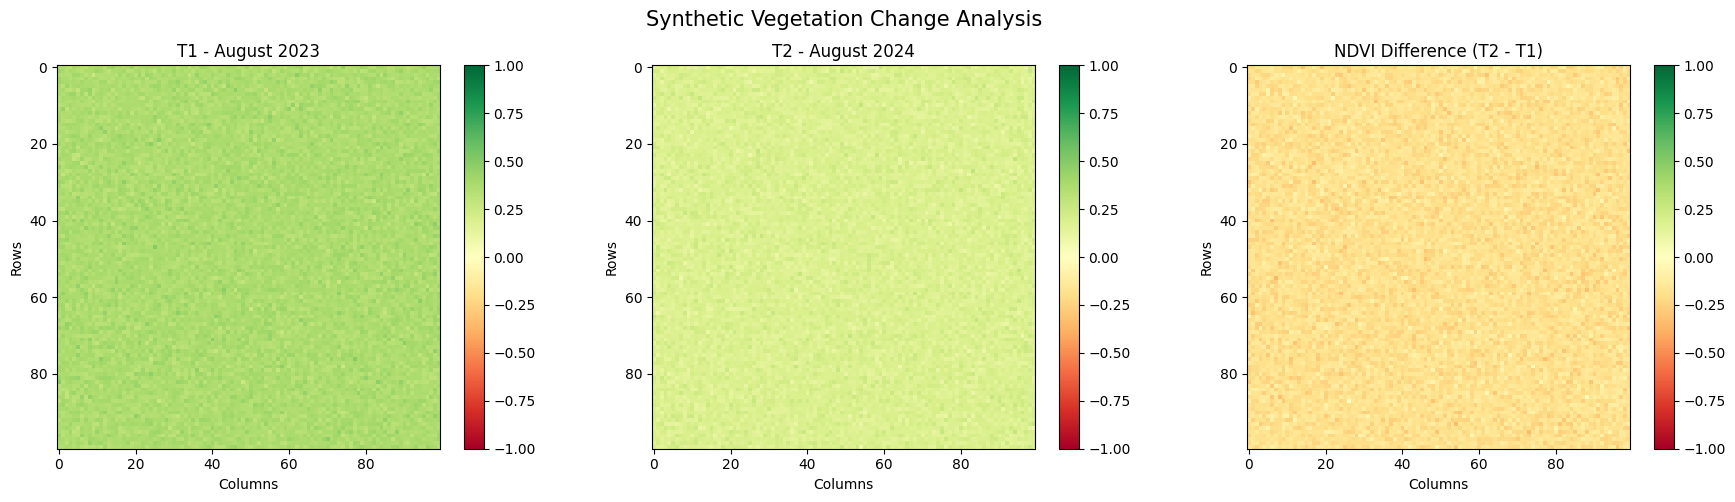

Vegetation comparison map saved successfully!


In [12]:
import matplotlib.pyplot as plt
import numpy as np
import os

# Calculate the difference between two dates
ndvi_difference = ndvi_t2 - ndvi_t1

# Create output folder
os.makedirs("outputs/maps", exist_ok=True)

# Generate three comparison maps
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# T1 vegetation map
image1 = axes[0].imshow(
    ndvi_t1,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)
axes[0].set_title("T1 - August 2023")
axes[0].set_xlabel("Columns")
axes[0].set_ylabel("Rows")
plt.colorbar(image1, ax=axes[0], fraction=0.046)

# T2 vegetation map
image2 = axes[1].imshow(
    ndvi_t2,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)
axes[1].set_title("T2 - August 2024")
axes[1].set_xlabel("Columns")
axes[1].set_ylabel("Rows")
plt.colorbar(image2, ax=axes[1], fraction=0.046)

# Difference map
image3 = axes[2].imshow(
    ndvi_difference,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)
axes[2].set_title("NDVI Difference (T2 - T1)")
axes[2].set_xlabel("Columns")
axes[2].set_ylabel("Rows")
plt.colorbar(image3, ax=axes[2], fraction=0.046)

plt.suptitle(
    "Synthetic Vegetation Change Analysis",
    fontsize=15
)

plt.tight_layout()

# Save comparison figure
plt.savefig(
    "outputs/maps/vegetation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Vegetation comparison map saved successfully!")

In [13]:
import numpy as np
import pandas as pd
import os

# Calculate difference
ndvi_difference = ndvi_t2 - ndvi_t1

# Calculate statistics
statistics = {
    "Metric": [
        "Mean NDVI",
        "Minimum NDVI",
        "Maximum NDVI",
        "Standard Deviation"
    ],
    "T1_Aug_2023": [
        np.mean(ndvi_t1),
        np.min(ndvi_t1),
        np.max(ndvi_t1),
        np.std(ndvi_t1)
    ],
    "T2_Aug_2024": [
        np.mean(ndvi_t2),
        np.min(ndvi_t2),
        np.max(ndvi_t2),
        np.std(ndvi_t2)
    ]
}

df = pd.DataFrame(statistics)

print("VEGETATION STATISTICS")
display(df.round(4))

# Calculate percentage change
mean_t1 = np.mean(ndvi_t1)
mean_t2 = np.mean(ndvi_t2)

percentage_change = (
    (mean_t2 - mean_t1) / mean_t1
) * 100

print("Average NDVI difference:",
      round(float(np.mean(ndvi_difference)), 4))

print("Percentage change:",
      round(float(percentage_change), 2), "%")

# Save statistics
os.makedirs("outputs/reports", exist_ok=True)

df.to_csv(
    "outputs/reports/vegetation_statistics.csv",
    index=False
)

print("Statistics CSV saved successfully!")

VEGETATION STATISTICS


,Metric,T1_Aug_2023,T2_Aug_2024
0,Mean NDVI,0.3690,0.1831
1,Minimum NDVI,0.2542,0.0758
2,Maximum NDVI,0.4999,0.2921
3,Standard Deviation,0.0320,0.0308


Average NDVI difference: -0.1859
Percentage change: -50.37 %
Statistics CSV saved successfully!


In [16]:
import rasterio
import numpy as np
import os

os.makedirs("outputs/rasters", exist_ok=True)

# Read reference raster metadata
with rasterio.open("data/raster/T1_August_2023.tif") as src:
    profile = src.profile.copy()

# Remove inherited block settings
profile.pop("blockxsize", None)
profile.pop("blockysize", None)

# Configure output raster
profile.update(
    driver="GTiff",
    count=1,
    dtype="float32",
    compress="lzw",
    tiled=False
)

ndvi_difference = ndvi_t2 - ndvi_t1

rasters = {
    "outputs/rasters/NDVI_T1_2023.tif": ndvi_t1,
    "outputs/rasters/NDVI_T2_2024.tif": ndvi_t2,
    "outputs/rasters/NDVI_Difference_2023_2024.tif": ndvi_difference
}

for filename, array in rasters.items():

    with rasterio.open(filename, "w", **profile) as dst:
        dst.write(array.astype("float32"), 1)

        dst.set_band_description(
            1,
            "NDVI Difference (T2 - T1)"
            if "Difference" in filename else "NDVI"
        )

    print("Successfully exported:", filename)

print("\nAll GeoTIFF files exported successfully!")

Successfully exported: outputs/rasters/NDVI_T1_2023.tif
Successfully exported: outputs/rasters/NDVI_T2_2024.tif
Successfully exported: outputs/rasters/NDVI_Difference_2023_2024.tif

All GeoTIFF files exported successfully!


In [15]:
import rasterio
import os

for filename in os.listdir("outputs/rasters"):

    path = os.path.join("outputs/rasters", filename)

    with rasterio.open(path) as src:

        print("\nFile:", filename)
        print("Dimensions:", src.width, "x", src.height)
        print("CRS:", src.crs)
        print("Bands:", src.count)
        print("Data type:", src.dtypes[0])


File: NDVI_Difference_2023_2024.tif
Dimensions: 100 x 100
CRS: EPSG:4326
Bands: 1
Data type: float32

File: NDVI_T2_2024.tif
Dimensions: 100 x 100
CRS: EPSG:4326
Bands: 1
Data type: float32

File: NDVI_T1_2023.tif
Dimensions: 100 x 100
CRS: EPSG:4326
Bands: 1
Data type: float32


In [17]:
import numpy as np
import pandas as pd
import os
from datetime import date

# Calculate statistics
mean_t1 = float(np.mean(ndvi_t1))
mean_t2 = float(np.mean(ndvi_t2))

difference = ndvi_t2 - ndvi_t1

mean_difference = float(np.mean(difference))

percentage_change = (
    (mean_t2 - mean_t1) / mean_t1
) * 100

# Pixel-level change classification
declined_pixels = np.sum(difference < -0.05)
stable_pixels = np.sum(
    (difference >= -0.05) & (difference <= 0.05)
)
improved_pixels = np.sum(difference > 0.05)

total_pixels = difference.size

# Generate report
report = f"""
GIS AND GEOSPATIAL STUDY
Two-Date Vegetation Comparison Report

1. PROJECT OBJECTIVE

To demonstrate raster and vector data processing,
coordinate reference systems, GeoJSON handling,
NDVI calculation and temporal vegetation comparison.

2. STUDY AREA

Study Area: Wetland Study Area
Location: Sample Region
CRS: EPSG:4326
Boundary Format: GeoJSON

Note: The study area is fictional and uses sample coordinates.

3. DATASETS

T1: August 2023
T2: August 2024

Both raster datasets contain:
- Red band
- Near-Infrared band
- 100 x 100 pixels
- EPSG:4326 coordinate reference system

4. METHODOLOGY

NDVI = (NIR - Red) / (NIR + Red)

NDVI Difference = T2 NDVI - T1 NDVI

5. RESULTS

Mean NDVI in August 2023: {mean_t1:.4f}
Mean NDVI in August 2024: {mean_t2:.4f}

Mean NDVI Difference: {mean_difference:.4f}
Percentage Change: {percentage_change:.2f}%

Total Pixels: {total_pixels}
Pixels with NDVI decline greater than 0.05: {declined_pixels}
Pixels with relatively stable NDVI: {stable_pixels}
Pixels with NDVI improvement greater than 0.05: {improved_pixels}

6. INTERPRETATION

The synthetic dataset shows a decrease in average NDVI
between the two observation dates.

This represents simulated vegetation greenness decline.
It does not establish actual environmental degradation.

7. OUTPUT FILES

- wetland_boundary.geojson
- wetland_boundary_map.html
- T1_August_2023.tif
- T2_August_2024.tif
- NDVI_T1_2023.tif
- NDVI_T2_2024.tif
- NDVI_Difference_2023_2024.tif
- vegetation_comparison.png
- vegetation_statistics.csv

8. LIMITATIONS

- Raster values are synthetically generated.
- The study boundary is fictional.
- No actual satellite imagery was used.
- Results are for educational demonstration only.

9. CONCLUSION

This exercise demonstrates a basic geospatial workflow
using Python, GeoPandas, Rasterio, NumPy, Pandas,
Matplotlib and Folium.

The workflow covers vector creation, GeoJSON export,
raster processing, NDVI calculation, temporal comparison
and geospatial output generation.
"""

os.makedirs("outputs/reports", exist_ok=True)

with open(
    "outputs/reports/GIS_Analysis_Report.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(report)

print(report)
print("\nAnalysis report saved successfully!")


GIS AND GEOSPATIAL STUDY
Two-Date Vegetation Comparison Report

1. PROJECT OBJECTIVE

To demonstrate raster and vector data processing,
coordinate reference systems, GeoJSON handling,
NDVI calculation and temporal vegetation comparison.

2. STUDY AREA

Study Area: Wetland Study Area
Location: Sample Region
CRS: EPSG:4326
Boundary Format: GeoJSON

Note: The study area is fictional and uses sample coordinates.

3. DATASETS

T1: August 2023
T2: August 2024

Both raster datasets contain:
- Red band
- Near-Infrared band
- 100 x 100 pixels
- EPSG:4326 coordinate reference system

4. METHODOLOGY

NDVI = (NIR - Red) / (NIR + Red)

NDVI Difference = T2 NDVI - T1 NDVI

5. RESULTS

Mean NDVI in August 2023: 0.3690
Mean NDVI in August 2024: 0.1831

Mean NDVI Difference: -0.1859
Percentage Change: -50.37%

Total Pixels: 10000
Pixels with NDVI decline greater than 0.05: 9994
Pixels with relatively stable NDVI: 6
Pixels with NDVI improvement greater than 0.05: 0

6. INTERPRETATION

The synthetic dat

In [18]:
# Display original CRS
print("Original CRS:", gdf.crs)

# Reproject geographic coordinates to UTM Zone 43N
gdf_projected = gdf.to_crs("EPSG:32643")

print("Reprojected CRS:", gdf_projected.crs)

# Display original and projected geometry
print("\nOriginal coordinates:")
print(gdf.geometry.iloc[0])

print("\nProjected coordinates:")
print(gdf_projected.geometry.iloc[0])

# Calculate area in square metres
area_sqm = gdf_projected.geometry.area.iloc[0]

print("\nStudy area:", round(area_sqm, 2), "square metres")
print("Study area:", round(area_sqm / 10000, 2), "hectares")

Original CRS: EPSG:4326
Reprojected CRS: EPSG:32643

Original coordinates:
POLYGON ((77.5 16.5, 77.6 16.5, 77.6 16.6, 77.5 16.6, 77.5 16.5))

Projected coordinates:
POLYGON ((766875.1303506589 1825898.2669658754, 777556.2061406288 1826033.3703912306, 777412.9923835922 1837104.998664073, 766737.4410987049 1836969.1696911568, 766875.1303506589 1825898.2669658754))

Study area: 118241470.69 square metres
Study area: 11824.15 hectares


In [19]:
import rasterio

with rasterio.open("data/raster/T1_August_2023.tif") as src:

    print("Raster CRS:", src.crs)
    print("Raster bounds:", src.bounds)
    print("Raster dimensions:", src.width, "x", src.height)
    print("Pixel resolution:", src.res)

Raster CRS: EPSG:4326
Raster bounds: BoundingBox(left=77.5, bottom=16.5, right=77.6, top=16.6)
Raster dimensions: 100 x 100
Pixel resolution: (0.001, 0.001)


In [22]:
readme = """
# GIS and Geospatial Study

## Project Overview

This project demonstrates a Python-based geospatial workflow
using synthetic raster and vector datasets.

The project explores:
- Raster and vector data.
- Coordinate Reference Systems (CRS).
- GeoJSON data handling.
- Geographic visualization.
- NDVI calculation.
- Two-date vegetation comparison.
- Raster statistics and GeoTIFF export.

## Technologies Used

- Python
- GeoPandas
- Rasterio
- NumPy
- Pandas
- Matplotlib
- Folium
- Shapely
- PyProj
- Google Colab

## Project Structure

GIS-Geospatial-Study/
|
|-- GIS_Geospatial_Study.ipynb
|-- wetland_boundary.geojson
|-- wetland_boundary_map.html
|
|-- data/
|   |-- raster/
|       |-- T1_August_2023.tif
|       |-- T2_August_2024.tif
|
|-- outputs/
|   |-- maps/
|   |   |-- vegetation_comparison.png
|   |   |-- NDVI_T1_2023.npy
|   |   |-- NDVI_T2_2024.npy
|   |
|   |-- rasters/
|   |   |-- NDVI_T1_2023.tif
|   |   |-- NDVI_T2_2024.tif
|   |   |-- NDVI_Difference_2023_2024.tif
|   |
|   |-- reports/
|       |-- vegetation_statistics.csv
|       |-- GIS_Analysis_Report.txt
|
|-- README.md

## Study Area

Name: Wetland Study Area

CRS: EPSG:4326

Boundary format: GeoJSON

The study area uses fictional coordinates for educational
demonstration purposes.

## Methodology

NDVI is calculated using:

NDVI = (NIR - Red) / (NIR + Red)

The temporal difference is calculated using:

NDVI Difference = T2 NDVI - T1 NDVI

## Results

| Metric | T1 August 2023 | T2 August 2024 |
|---|---:|---:|
| Mean NDVI | 0.3690 | 0.1831 |
| Minimum NDVI | 0.2542 | 0.0758 |
| Maximum NDVI | 0.4999 | 0.2921 |
| Standard Deviation | 0.0320 | 0.0308 |

Mean NDVI difference: -0.1859

Percentage change: -50.37%

## CRS and Georeferencing
Projected CRS: EPSG:32643
Study area: 118.24 square kilometres
Study area: 11,824.15 hectares


Raster pixel resolution: 0.001 x 0.001 degrees.

#Clarify the data source

Data Source: Synthetically generated raster data.
Satellite imagery: Not used.
Purpose: Educational geospatial analysis.

#Explain the NDVI interpretation

A negative NDVI difference indicates a decrease in
vegetation greenness between the two observation dates.




## Limitations

- Raster data is synthetically generated.
- The study boundary is fictional.
- No real satellite imagery was used.
- The results are not evidence of actual environmental
  degradation or wetland loss.

## Conclusion

This project demonstrates a basic geospatial analysis
workflow involving vector creation, GeoJSON export,
raster processing, CRS transformation, NDVI calculation,
temporal comparison and geospatial visualization.

## How to Run

1. Open GIS_Geospatial_Study.ipynb in Google Colab.
2. Install the required Python libraries.
3. Run all notebook cells sequentially.
4. Review the generated maps, statistics and reports.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md created successfully!")

README.md created successfully!


In [23]:
with open("README.md", "r", encoding="utf-8") as file:
    print(file.read())


# GIS and Geospatial Study

## Project Overview

This project demonstrates a Python-based geospatial workflow
using synthetic raster and vector datasets.

The project explores:
- Raster and vector data.
- Coordinate Reference Systems (CRS).
- GeoJSON data handling.
- Geographic visualization.
- NDVI calculation.
- Two-date vegetation comparison.
- Raster statistics and GeoTIFF export.

## Technologies Used

- Python
- GeoPandas
- Rasterio
- NumPy
- Pandas
- Matplotlib
- Folium
- Shapely
- PyProj
- Google Colab

## Project Structure

GIS-Geospatial-Study/
|
|-- GIS_Geospatial_Study.ipynb
|-- wetland_boundary.geojson
|-- wetland_boundary_map.html
|
|-- data/
|   |-- raster/
|       |-- T1_August_2023.tif
|       |-- T2_August_2024.tif
|
|-- outputs/
|   |-- maps/
|   |   |-- vegetation_comparison.png
|   |   |-- NDVI_T1_2023.npy
|   |   |-- NDVI_T2_2024.npy
|   |
|   |-- rasters/
|   |   |-- NDVI_T1_2023.tif
|   |   |-- NDVI_T2_2024.tif
|   |   |-- NDVI_Difference_2023_2024.tif
|   |
| 